Размер исходного изображения: (512, 512)


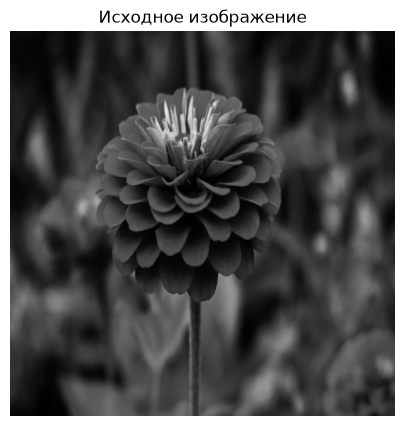

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image_path = 'img.jpg'

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

img = cv2.resize(img, (512, 512), interpolation=cv2.INTER_AREA)
img = img.astype(np.float64)

print('Размер исходного изображения:', img.shape)

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.axis('off')
plt.show()

# 1. Реализация преобразования Хаара

In [2]:
def haar_rows(img):
    a = img[:, 0::2]
    b = img[:, 1::2]
    approx = (a + b) / 2
    detail = (a - b) / 2
    return np.concatenate([approx, detail], axis=1)


def haar_2d(img):
    rows = haar_rows(img)
    return haar_rows(rows.T).T

# 2. Три ступени преобразования Хаара

Ступень 1: преобразуем всё изображение 512×512.
Ступень 2: повторно преобразуем область LL размером 256×256.
Ступень 3: повторно преобразуем область LL размером 128×128.

In [3]:
lvl1 = haar_2d(img)

lvl2 = lvl1.copy()
lvl2[:256, :256] = haar_2d(lvl1[:256, :256])

lvl3 = lvl2.copy()
lvl3[:128, :128] = haar_2d(lvl2[:128, :128])

# 3. Результаты преобразования по уровням

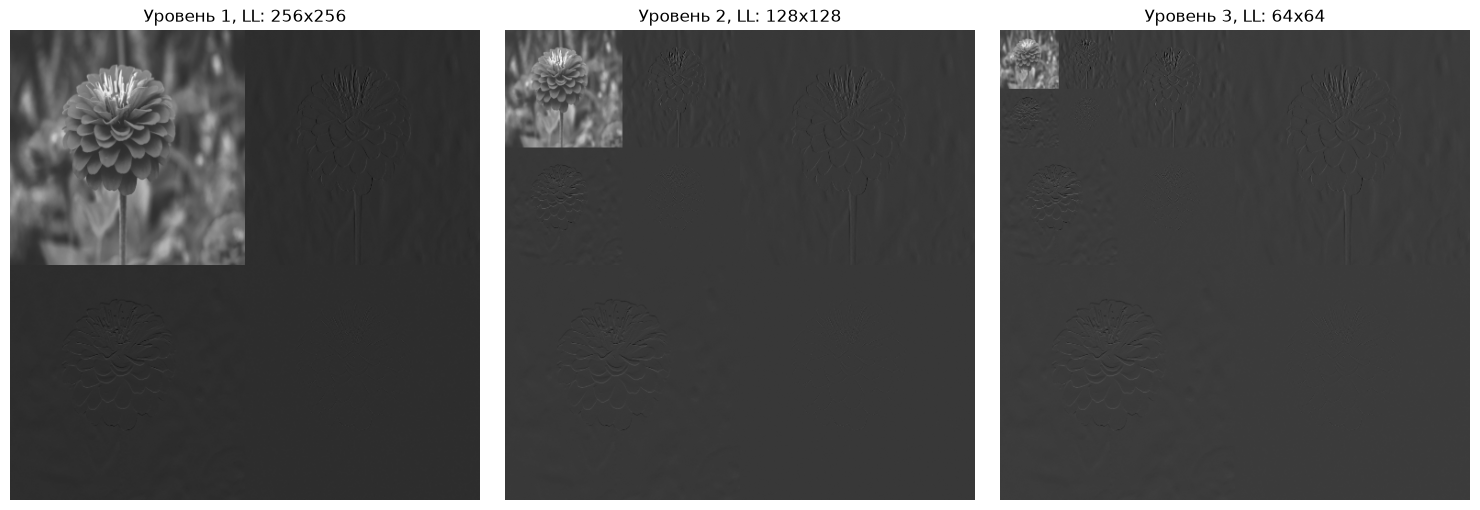

In [20]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(lvl1, cmap='gray')
plt.title('Уровень 1, LL: 256x256')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(lvl2, cmap='gray')
plt.title('Уровень 2, LL: 128x128')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(lvl3, cmap='gray')
plt.title('Уровень 3, LL: 64x64')
plt.axis('off')

plt.tight_layout()
plt.show()

# 4. Результаты сжатия

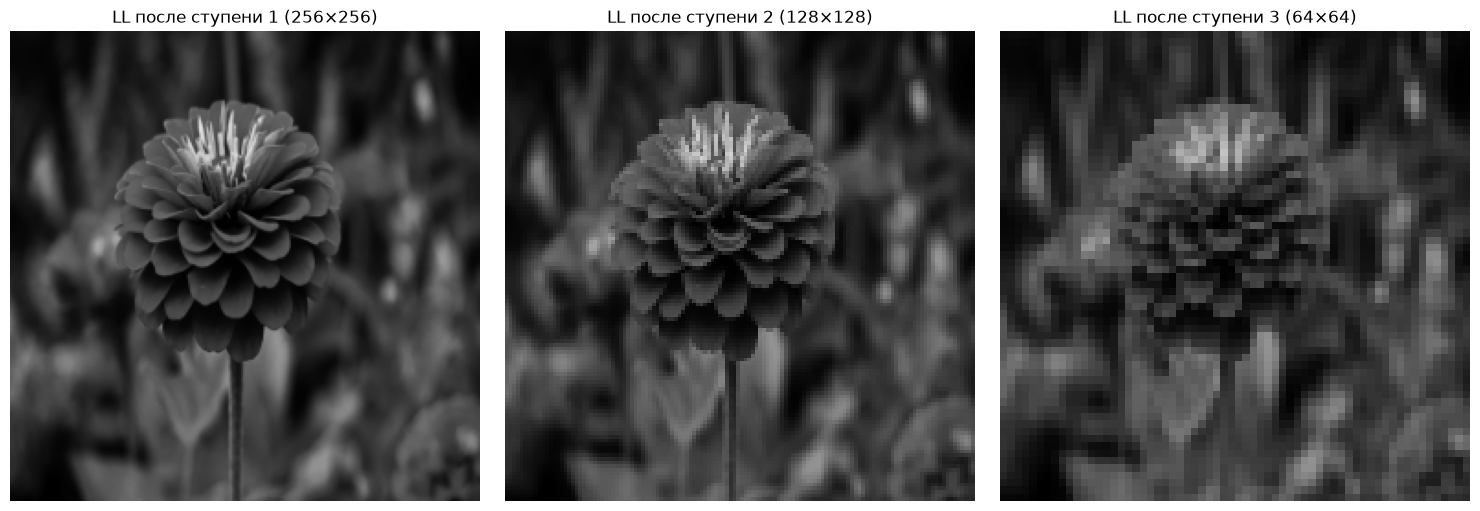

In [7]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(lvl1[:256, :256], cmap='gray', vmin=0, vmax=255)
plt.title('LL после ступени 1 (256×256)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(lvl2[:128, :128], cmap='gray', vmin=0, vmax=255)
plt.title('LL после ступени 2 (128×128)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(lvl3[:64, :64], cmap='gray', vmin=0, vmax=255)
plt.title('LL после ступени 3 (64×64)')
plt.axis('off')

plt.tight_layout()
plt.show()

# Вывод

В работе реализовано двумерное преобразование Хаара для изображения размером 512×512. Выполнены три ступени разложения, на каждом следующем шаге преобразуется только область LL предыдущего уровня. Получены и отображены общие матрицы коэффициентов после каждой ступени, а также соответствующие области средних коэффициентов размером 256×256, 128×128 и 64×64.